In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

In [2]:
df = pd.read_csv('new_train.csv')

In [14]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,y
0,49,blue-collar,married,basic.9y,unknown,no,no,cellular,nov,wed,227,4,999,0,nonexistent,no
1,37,entrepreneur,married,university.degree,no,no,no,telephone,nov,wed,202,2,999,1,failure,no
2,78,retired,married,basic.4y,no,no,no,cellular,jul,mon,1148,1,999,0,nonexistent,yes
3,36,admin.,married,university.degree,no,yes,no,telephone,may,mon,120,2,999,0,nonexistent,no
4,59,retired,divorced,university.degree,no,no,no,cellular,jun,tue,368,2,999,0,nonexistent,no


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32950 entries, 0 to 32949
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          32950 non-null  int64 
 1   job          32950 non-null  object
 2   marital      32950 non-null  object
 3   education    32950 non-null  object
 4   default      32950 non-null  object
 5   housing      32950 non-null  object
 6   loan         32950 non-null  object
 7   contact      32950 non-null  object
 8   month        32950 non-null  object
 9   day_of_week  32950 non-null  object
 10  duration     32950 non-null  int64 
 11  campaign     32950 non-null  int64 
 12  pdays        32950 non-null  int64 
 13  previous     32950 non-null  int64 
 14  poutcome     32950 non-null  object
 15  y            32950 non-null  object
dtypes: int64(5), object(11)
memory usage: 4.0+ MB


In [16]:
df.describe()

,age,duration,campaign,pdays,previous
count,32950.000000,32950.000000,32950.000000,32950.000000,32950.000000
mean,40.014112,258.127466,2.560607,962.052413,0.174719
std,10.403636,258.975917,2.752326,187.951096,0.499025
min,17.000000,0.000000,1.000000,0.000000,0.000000
25%,32.000000,103.000000,1.000000,999.000000,0.000000
50%,38.000000,180.000000,2.000000,999.000000,0.000000
75%,47.000000,319.000000,3.000000,999.000000,0.000000
max,98.000000,4918.000000,56.000000,999.000000,7.000000


In [3]:
p = (df["y"] == "yes").mean()

In [4]:
n = 20

In [5]:
print("Total records in dataset:", len(df))
print("Success probability (p):", p)

Total records in dataset: 32950
Success probability (p): 0.11265553869499241


In [6]:
x = np.arange(0, n + 1)

In [7]:
pmf = binom.pmf(x, n, p)
cdf = binom.cdf(x, n, p)

In [8]:
mean, var = binom.stats(n, p, moments="mv")
std_dev = np.sqrt(var)

In [9]:
print("Mean (Expected successes):", mean)
print("Variance:", var)
print("Standard Deviation:", std_dev)

Mean (Expected successes): 2.253110773899848
Variance: 1.9992853659266694
Standard Deviation: 1.4139608784993556


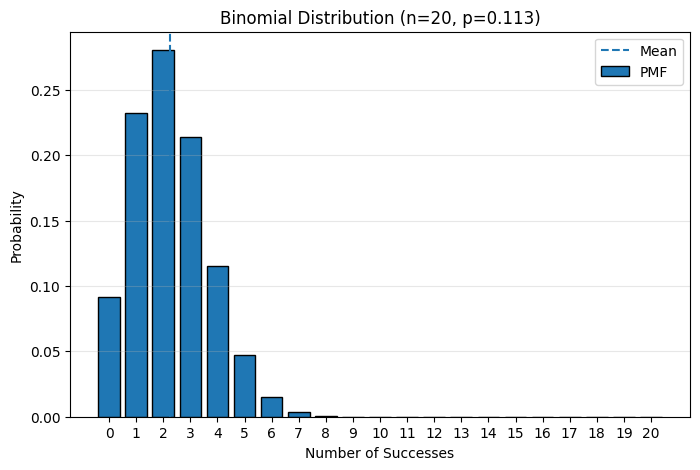

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    x,
    pmf,
    edgecolor="black",
    label="PMF"
)

plt.axvline(
    mean,
    linestyle="--",
    label="Mean"
)

plt.title(f"Binomial Distribution (n={n}, p={p:.3f})")
plt.xlabel("Number of Successes")
plt.ylabel("Probability")
plt.xticks(x)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [12]:
p_at_least_5 = 1 - binom.cdf(4, n, p)

print("P(X >= 5):", p_at_least_5)


P(X >= 5): 0.06640899663997135


In [13]:
p_exactly_8 = binom.pmf(8, n, p)

print("P(X = 8):", p_exactly_8)

P(X = 8): 0.0007787434956761516
